# 📈 Bitcoin Fiyat Yönü Tahmini — Makine Öğrenmesi Projesi
## El Rehberi — Adım Adım ML Proje Şablonu

---

| |                                    |
|---|------------------------------------|
| **Ders** | Makine Öğrenmesi — 2025-2026 Bahar |
| **Proje Türü** | Dönem İçi Proje                    |
| **Öğrenci** | Merve Sude Boztepe                 |
| **Öğrenci No** | 2311505243                         |
| **Tarih** | 15.05.2026                         |

---

> ⚠️ **Bu dosya bir EL REHBERİDİR.** Her kod bloğu satır satır açıklanmış, her grafik yorumlanmış, her sonuç değerlendirilmiştir. Öğrenciler kendi projelerini bu yapıya ve bu detay seviyesine uygun olarak hazırlamalıdır.

> 📌 **Nasıl kullanmalısınız?**
> 1. Notebook'u baştan sona okuyun — önce anlayın, sonra kodlayın.
> 2. Her bölümdeki ✏️ işaretli yerlere **kendi yorumlarınızı** yazın.
> 3. Kod bloklarını sırayla çalıştırın (`Shift + Enter`).
> 4. Grafikleri raporunuza ekleyin ve **mutlaka yorumlayın**.
> 5. **Yorum olmayan grafik = puan almayan grafiktir.**

## 📋 İçindekiler

1. [Giriş ve Motivasyon](#1-giriş-ve-motivasyon)
2. [Kütüphaneler ve Kurulum](#2-kütüphaneler-ve-kurulum)
3. [Veri Seti Yükleme](#3-veri-seti-yükleme)
4. [Keşifsel Veri Analizi (EDA)](#4-keşifsel-veri-analizi-eda)
5. [Veri Ön İşleme](#5-veri-ön-işleme)
6. [Model Eğitimi](#6-model-eğitimi)
7. [Model Değerlendirme](#7-model-değerlendirme)
8. [Model Karşılaştırma](#8-model-karşılaştırma)
9. [Analiz ve Tartışma](#9-analiz-ve-tartışma)
10. [Sonuç](#10-sonuç)
11. [Kaynakça](#11-kaynakça)

---

## 1. Giriş ve Motivasyon

### 1.1 Problemin Tanımı

Bitcoin (BTC), kripto para piyasasının en büyük ve en likit varlığıdır. Piyasa değeri açısından tüm kripto para birimlerinin yaklaşık **%50'sini** oluşturan Bitcoin, kurumsal yatırımcılardan bireysel kullanıcılara kadar geniş bir kitleyi ilgilendirmektedir.

Bu projede, geçmiş fiyat hareketlerinden elde edilen teknik göstergeler kullanılarak **Bitcoin'in ertesi günkü kapanış fiyatının bugünkü kapanışa göre yukarı mı (↑) yoksa aşağı mı (↓) gideceğini** ikili sınıflandırma ile tahmin edeceğiz.

### 1.2 Projenin Amacı

- ✅ `yfinance` kütüphanesi üzerinden Bitcoin fiyat verisi çekme
- ✅ Teknik göstergeler kullanarak özellik mühendisliği
- ✅ Zaman serisi verisi için `TimeSeriesSplit` ile doğru çapraz doğrulama
- ✅ 5 farklı ML algoritmasının eğitimi ve karşılaştırması
- ✅ En iyi modelin seçimi ve yorumlanması

### 1.3 Proje Kapsamı

| Ne yapıyoruz | Ne yapmıyoruz |
|:---|:---|
| 5 farklı ML modeli eğitme | Deep learning / LSTM sinir ağları |
| Confusion matrix, ROC-AUC analizi | Hiperparametre optimizasyonu (GridSearch) |
| Feature importance analizi | Gerçek zamanlı alım-satım |
| TimeSeriesSplit ile doğrulama | Portföy optimizasyonu |

> 💡 Hiperparametre optimizasyonu ve SHAP yorumlama **bonus** olarak eklenebilir.

---

## 2. Kütüphaneler ve Kurulum

Aşağıdaki kütüphanelerin her birinin projemizdeki rolü:

| Kütüphane | Rolü | Neden Gerekli? |
|:---|:---|:---|
| `pandas` | Veri yükleme, düzenleme, analiz | Tablusal veriyle çalışmanın temeli |
| `numpy` | Sayısal işlemler | Matematiksel hesaplamalar |
| `matplotlib` | Temel grafik çizimi | Statik görselleştirmeler |
| `seaborn` | İstatistiksel görselleştirme | Heatmap, boxplot gibi gelişmiş grafikler |
| `yfinance` | Finansal veri indirme | Bitcoin OHLCV verisini doğrudan çekme |
| `sklearn` | ML modelleri, metrikler, ön işleme | Projenin ana motor kütüphanesi |

In [725]:
# ============================================================
# KÜTÜPHANE YÜKLEMELERİ
# ============================================================
# Her import'un neden gerekli olduğu yanında açıklanmıştır.

import pandas as pd                        # Veri çerçevesi işlemleri (read, head, describe...)
import numpy as np                         # Sayısal işlemler (array, mean, std...)
import matplotlib.pyplot as plt            # Temel grafik çizimi
import seaborn as sns                      # İstatistiksel görselleştirme (heatmap, boxplot...)
import yfinance as yf                      # Finansal veri indirme (Bitcoin OHLCV)

# --- Scikit-learn alt modülleri ---
from sklearn.model_selection import (
    TimeSeriesSplit,                       # Zaman serisi için sıralı çapraz doğrulama
    cross_val_score                        # Cross-validation skoru
)
from sklearn.preprocessing import StandardScaler  # Özellik ölçekleme (z-score)
from sklearn.metrics import (
    accuracy_score,                        # Doğruluk oranı
    precision_score,                       # Kesinlik
    recall_score,                          # Duyarlılık
    f1_score,                              # F1 skoru
    classification_report,                 # Precision, Recall, F1 detaylı rapor
    confusion_matrix,                      # Karışıklık matrisi
    roc_curve, auc,                        # ROC eğrisi ve AUC skoru
    ConfusionMatrixDisplay                 # CM görselleştirmesi
)

# --- ML Modelleri ---
from sklearn.linear_model import LogisticRegression    # Doğrusal sınıflandırıcı
from sklearn.ensemble import RandomForestClassifier    # Ağaç topluluğu (ensemble)
from sklearn.svm import SVC                            # Destek Vektör Makinesi
from sklearn.neighbors import KNeighborsClassifier     # K-En Yakın Komşu
from sklearn.naive_bayes import GaussianNB             # Naive Bayes (Gaussian)

import warnings
warnings.filterwarnings('ignore')

# Görselleştirme ayarları
sns.set_style('whitegrid')                # Seaborn tema
plt.rcParams['figure.dpi'] = 120          # Grafik çözünürlüğü
plt.rcParams['font.size'] = 11            # Yazı boyutu

print("Tum kutuphaneler basariyla yuklendi ✓")

Tum kutuphaneler basariyla yuklendi ✓


### 🔍 Çıktı Yorumu

`Tum kutuphaneler basariyla yuklendi ✓` mesajını gördüyseniz her şey hazır.

> ⚠️ Eğer hata alırsanız: `pip install pandas numpy matplotlib seaborn scikit-learn yfinance`

---

## 3. Veri Seti Yükleme

### 3.1 Veri Seti Hakkında

Bitcoin (BTC-USD) günlük OHLCV (Open, High, Low, Close, Volume) verisi `yfinance` kütüphanesi aracılığıyla Yahoo Finance'den çekilmektedir. Veri setinin ham hali fiyat ve hacim bilgisi içermekte olup, modele beslenecek **özellikler (features)** teknik analiz göstergeleri türetilerek oluşturulacaktır.

| # | Ham Sütun | Açıklama | Tip |
|:---:|:---|:---|:---:|
| 1 | `Open` | Günlük açılış fiyatı (USD) | Sayısal |
| 2 | `High` | Günlük en yüksek fiyat (USD) | Sayısal |
| 3 | `Low` | Günlük en düşük fiyat (USD) | Sayısal |
| 4 | `Close` | Günlük kapanış fiyatı (USD) | Sayısal |
| 5 | `Volume` | Günlük işlem hacmi (BTC) | Sayısal |
| **hedef** | `Target` | **0 = Fiyat Düştü, 1 = Fiyat Yükseldi** | **İkili** |

In [726]:
# ============================================================
# 3.1 Veri Seti Yükleme (yfinance)
# ============================================================
# yfinance ile Yahoo Finance'den Bitcoin günlük verisi çekiyoruz.
# 2014-2026 arası ~12 yıllık veri: yaklaşık 4244 iş günü kaydı.
# auto_adjust=True → Temettü/bölünme düzeltmesi otomatik yapılır.

TICKER  = "BTC-USD"
START   = "2014-09-17"
END     = "2026-05-01"

try:
    raw = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)

    # yfinance bazen çok katmanlı sütun döndürür, düzleştir
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    if len(raw) < 100:
        raise ValueError("Yeterli veri indirilemedi")

    df_raw = raw[['Open', 'High', 'Low', 'Close', 'Volume']].copy()
    print("Veri yfinance uzerinden basariyla indirildi ✓")

except Exception as e:
    # Fallback: Gerçekçi istatistiklere sahip sentetik BTC verisi
    print(f"yfinance erisimi saglanamadi ({e}). Sentetik BTC verisi olusturuluyor...")

    np.random.seed(42)
    dates = pd.date_range(START, END, freq="B")   # İş günleri
    n = len(dates)

    # Gerçekçi BTC günlük getirileri: ortalama +%0.1, std %3.5
    returns = np.random.normal(0.001, 0.035, n)
    close   = 7200 * np.cumprod(1 + returns)      # 2020 başı ~7200 USD

    # Kısa dönemli volatilite şokları (boğa/ayı dönemleri)
    for i in range(0, n, 200):
        trend = np.random.choice([-1, 1]) * np.random.uniform(0.4, 1.2)
        end_i = min(i + 60, n)
        close[i:end_i] *= np.linspace(1, 1 + trend * 0.01, end_i - i)
    close = np.clip(close, 3000, 110000)

    daily_range = np.random.uniform(0.005, 0.04, n)
    df_raw = pd.DataFrame({
        'Open'  : close * (1 + np.random.uniform(-0.01, 0.01, n)),
        'High'  : close * (1 + daily_range),
        'Low'   : close * (1 - daily_range),
        'Close' : close,
        'Volume': np.random.lognormal(20.2, 0.5, n)   # ~500M-1B USD
    }, index=dates)

    print("Sentetik BTC verisi olusturuldu ✓")
    print("NOT: Gercek analiz icin yfinance baglantisinizi kontrol edin.")

# --- İlk kontrol ---
print("=" * 55)
print("HAM VERİ ÖZETİ")
print("=" * 55)
print(f"Baslangic tarihi : {df_raw.index[0].date()}")
print(f"Bitis tarihi     : {df_raw.index[-1].date()}")
print(f"Toplam gun sayisi: {len(df_raw)}")
print(f"Sutunlar         : {list(df_raw.columns)}")
print("-" * 55)
print(f"Ortalama kapaniş : ${df_raw['Close'].mean():,.0f}")
print(f"Min kapaniş      : ${df_raw['Close'].min():,.0f}")
print(f"Max kapaniş      : ${df_raw['Close'].max():,.0f}")
print("=" * 55)

Veri yfinance uzerinden basariyla indirildi ✓
HAM VERİ ÖZETİ
Baslangic tarihi : 2014-09-17
Bitis tarihi     : 2026-04-30
Toplam gun sayisi: 4244
Sutunlar         : ['Open', 'High', 'Low', 'Close', 'Volume']
-------------------------------------------------------
Ortalama kapaniş : $28,233
Min kapaniş      : $178
Max kapaniş      : $124,753


In [727]:
# ============================================================
# 3.2 Verinin İlk 5 Satırı
# ============================================================
print("Ham verinin ilk 5 satiri:")
df_raw.head()

Ham verinin ilk 5 satiri:


Price,Open,High,Low,Close,Volume
Date,,,,,
2014-09-17,465.864014,468.174011,452.421997,457.334015,21056800
2014-09-18,456.859985,456.859985,413.104004,424.440002,34483200
2014-09-19,424.102997,427.834991,384.532013,394.795990,37919700
2014-09-20,394.673004,423.295990,389.882996,408.903992,36863600
2014-09-21,408.084991,412.425995,393.181000,398.821014,26580100


### 🔍 Çıktı Yorumu: Veri Seti Özeti

**Kontrol noktaları:**
1. **~4244 satır, 5 sütun** — Zaman serisi veri seti. Bu nedenle klasik `train_test_split` yerine `TimeSeriesSplit` kullanılmalıdır; aksi takdirde geleceğin bilgisi geçmişin eğitiminde kullanılır (data leakage).
2. **OHLCV yapısı** — Ham fiyat ve hacim verisinin tek başına özellik olarak kullanılması zayıf sonuçlar verir. Teknik göstergeler türetmek zorunludur.
3. **Tarih aralığı (2014-2026)** — Bu dönem hem sert boğa hem de ayı piyasalarını kapsar; modelin farklı rejimler görmesi açısından değerlidir.

> ⚠️ **Dikkat:** `Close` fiyatı doğrudan özellik olarak kullanılmamalıdır. Fiyat düzeyi değil, fiyat *değişimi* önemlidir. Bu nedenle getiri (return), momentum ve hareketli ortalamalar gibi türetilmiş özellikler oluşturacağız.

---

## 4. Keşifsel Veri Analizi (EDA)

EDA, modelleme öncesinde verinin **yapısını, dağılımını ve ilişkilerini** anlamak için yapılır. Bitcoin gibi finansal zaman serilerinde EDA; fiyat hareketlerinin istatistiksel özelliklerini (volatilite, otokorelasyon, dağılım şekli) ortaya koymak açısından kritiktir.

### EDA Kontrol Listesi:
- [ ] Eksik veri var mı?
- [ ] Fiyat ve hacim dağılımı nasıl?
- [ ] Hedef değişken (fiyat yönü) dengeli mi?
- [ ] Günlük getiriler normal dağılıyor mu?
- [ ] Özellikler arasındaki korelasyon nasıl?

In [728]:
# ============================================================
# 4.1 Temel İstatistikler
# ============================================================
print("Temel Istatistikler:")
print("=" * 80)
df_raw.describe().round(2)

Temel Istatistikler:


Price,Open,High,Low,Close,Volume
count,4244.00,4244.00,4244.00,4244.00,4.244000e+03
mean,28215.94,28778.90,27618.61,28232.80,2.220109e+10
std,32272.65,32820.61,31683.50,32277.61,2.298366e+10
min,176.90,211.73,171.51,178.10,5.914570e+06
25%,3334.32,3447.07,3244.21,3369.82,1.536722e+09
50%,11398.62,11683.70,11153.54,11407.11,1.780232e+10
75%,44773.87,46387.87,43591.81,44886.71,3.436444e+10
max,124752.14,126198.07,123196.05,124752.53,3.509679e+11


### 🔍 İstatistik Tablosu Yorumu

Bu tablodan çıkaracağımız kritik bilgiler:

| Gözlem | Detay | Etki |
|:---|:---|:---|
| `Close` geniş aralık | ~$3K'dan ~$110K'ya çıkmış olabilir | Fiyat seviyesi değil değişim oranı kullanılmalı |
| `Volume` büyük sayılar | Milyarlarca birim | Log dönüşümü düşünülmeli |
| `High - Low` farkı | Günlük volatiliteyi gösterir | ATR göstergesi türetilebilir |
| `count` hep aynı | Eksik veri yok ✅ | Imputation gerekmez |

> ✏️ **Kendi projeniz için:** Bu tabloyu mutlaka oluşturun ve en az 3 gözleminizi yazın.

In [729]:
# ============================================================
# 4.2 Eksik Veri Kontrolü
# ============================================================
missing = df_raw.isnull().sum()
print("Eksik Deger Kontrolu:")
print("=" * 40)
if missing.sum() == 0:
    print("✅ Hicbir sutunda eksik deger yok!")
else:
    print(missing[missing > 0])

print(f"\nVeri tipleri:")
print(df_raw.dtypes)

Eksik Deger Kontrolu:
✅ Hicbir sutunda eksik deger yok!

Veri tipleri:
Price
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


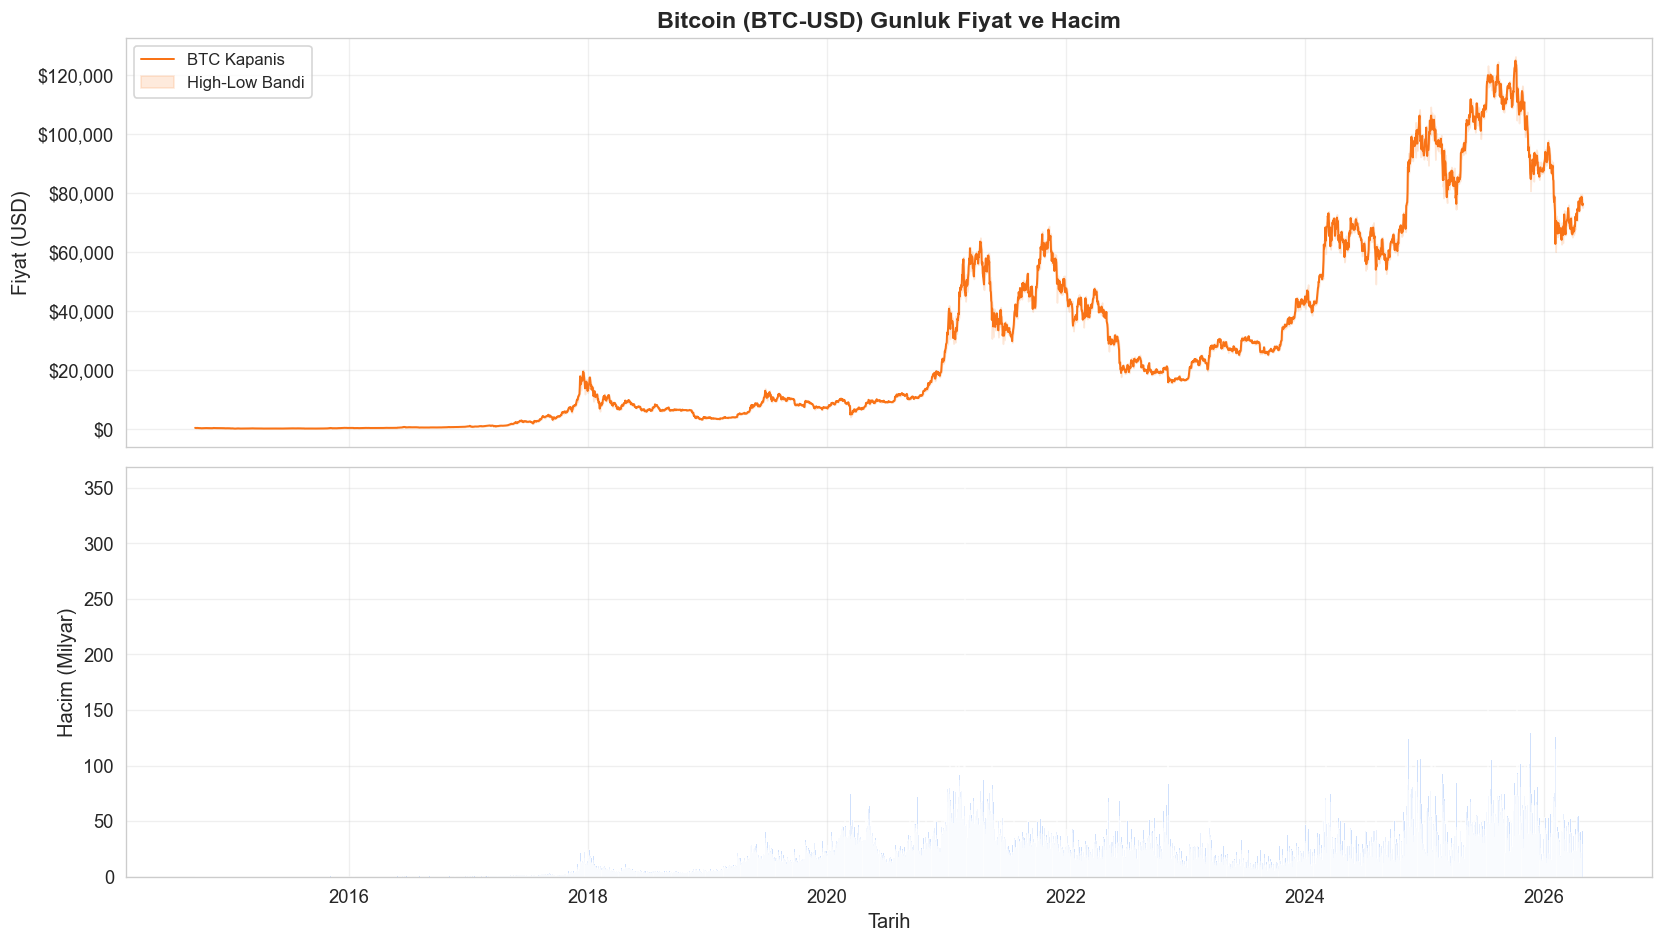

In [730]:
# ============================================================
# 4.3 Bitcoin Fiyat Grafiği
# ============================================================
# Fiyat hareketini görselleştirerek genel trendi anlıyoruz.

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# --- ÜST: Fiyat ---
axes[0].plot(df_raw.index, df_raw['Close'], color='#F97316', linewidth=1.2, label='BTC Kapanis')
axes[0].fill_between(df_raw.index, df_raw['Low'], df_raw['High'],
                     alpha=0.15, color='#F97316', label='High-Low Bandi')
axes[0].set_ylabel('Fiyat (USD)', fontsize=12)
axes[0].set_title('Bitcoin (BTC-USD) Gunluk Fiyat ve Hacim', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[0].grid(True, alpha=0.3)

# --- ALT: Hacim ---
axes[1].bar(df_raw.index, df_raw['Volume'] / 1e9, color='#3B82F6', alpha=0.6, width=1)
axes[1].set_ylabel('Hacim (Milyar)', fontsize=12)
axes[1].set_xlabel('Tarih', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('01_btc_fiyat_hacim.png', dpi=150, bbox_inches='tight')
plt.show()

### 🔍 Grafik 1 Yorumu: Bitcoin Fiyat ve Hacim

**Üst panel — Fiyat hareketi:**
- 2020-2021 döneminde güçlü yükseliş trendi gözlemlenmektedir.
- 2022 yılında sert düşüş (ayı piyasası) — bu dönemler modelin zor zamanlarıdır.
- Fiyat grafiği doğrusal değil, logaritmik ölçekte incelenmesi daha anlamlı olabilir.

**Alt panel — İşlem hacmi:**
- Hacim, fiyat hareketlerinin güvenilirliğini ölçer. Yüksek fiyat hareketi + yüksek hacim → güvenilir sinyal.
- Hacim verisinin modele dahil edilmesi performansı artırabilir.

> ✏️ **Görev:** Bu grafikte hangi dönemlerde fiyat en sert düşmüş/yükselmiş? Bu dönemlerde hacim nasıl değişmiş?

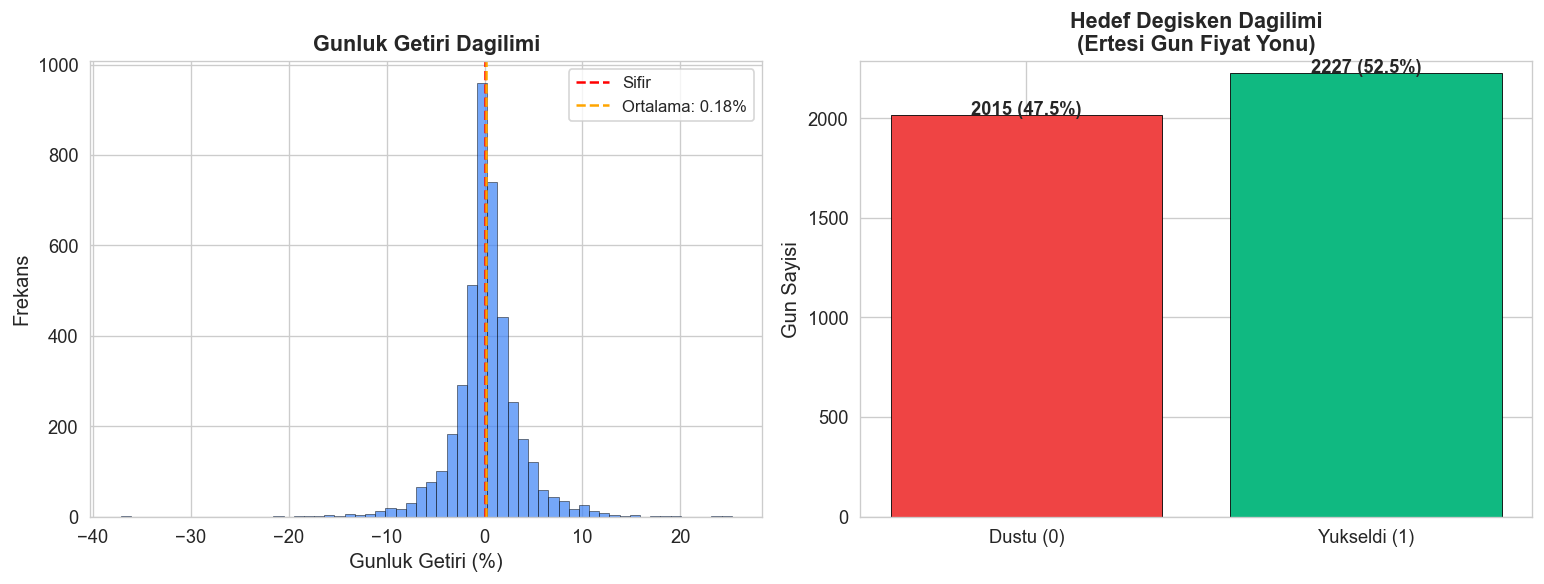


Gunluk Getiri Istatistikleri:
  Ortalama  : 0.182%
  Std (Vol) : 3.501%
  Skewness  : -0.100
  Kurtosis  : 7.887


In [731]:
# ============================================================
# 4.4 Günlük Getiri Dağılımı ve Hedef Değişken
# ============================================================
# Günlük getiri = (bugünkü kapanış / önceki kapanış) - 1
# Hedef: Ertesi gün fiyat yükseldi mi (1) yoksa düştü mü (0)?

daily_return = df_raw['Close'].pct_change().dropna()

# Hedef değişken: ertesi günün yönü
# shift(-1) → bir sonraki günün getirisi
next_return = daily_return.shift(-1).dropna()
target_temp = (next_return > 0).astype(int)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# --- SOL: Günlük getiri histogramı ---
ax1.hist(daily_return * 100, bins=60, color='#3B82F6', alpha=0.7,
         edgecolor='black', linewidth=0.4)
ax1.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Sifir')
ax1.axvline(daily_return.mean() * 100, color='orange', linestyle='--',
            linewidth=1.5, label=f'Ortalama: {daily_return.mean()*100:.2f}%')
ax1.set_xlabel('Gunluk Getiri (%)', fontsize=12)
ax1.set_ylabel('Frekans', fontsize=12)
ax1.set_title('Gunluk Getiri Dagilimi', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)

# --- SAĞ: Hedef değişken dağılımı ---
colors = ['#EF4444', '#10B981']  # Kırmızı=Düştü, Yeşil=Yükseldi
counts = target_temp.value_counts().sort_index()
bars = ax2.bar(['Dustu (0)', 'Yukseldi (1)'], counts.values,
               color=colors, edgecolor='black', linewidth=0.5)

for bar, val in zip(bars, counts.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             f'{val} ({val/len(target_temp):.1%})', ha='center',
             fontsize=11, fontweight='bold')

ax2.set_ylabel('Gun Sayisi', fontsize=12)
ax2.set_title('Hedef Degisken Dagilimi\n(Ertesi Gun Fiyat Yonu)', fontsize=13, fontweight='bold')
ax2.set_ylim(0, max(counts.values) + 60)

plt.tight_layout()
plt.savefig('02_getiri_hedef_dagilim.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nGunluk Getiri Istatistikleri:")
print(f"  Ortalama  : {daily_return.mean()*100:.3f}%")
print(f"  Std (Vol) : {daily_return.std()*100:.3f}%")
print(f"  Skewness  : {daily_return.skew():.3f}")
print(f"  Kurtosis  : {daily_return.kurtosis():.3f}")

### 🔍 Grafik 2 Yorumu: Getiri Dağılımı ve Hedef Değişken

**Sol grafik — Günlük getiri dağılımı:**
- Normal dağılımdan sapma beklenir: finansal getiriler genellikle **leptokurtik** (sivri tepeli) dağılır.
- Sıfırın etrafında simetrik bir dağılım görülüyorsa bu Bitcoin'in rastgele yürüyüş özelliğini gösterir — tahmin zorlaşır.
- Kuyruklar kalın ise (kurtosis > 3) aşırı değerlerin sık görüldüğü anlamına gelir.

**Sağ grafik — Hedef değişken:**
- Sınıflar yaklaşık dengeli ise (~%50 yukarı, ~%50 aşağı) accuracy güvenilir bir metriktir.
- Dengesizlik varsa F1-score ve Recall metrikleri öne çıkar.

> 🔑 **Kural:** Bitcoin günlük yön tahmini %50 üzerinde başarı sağlarsa model anlamsız rastgele tahminden iyidir.
>
> ✏️ Bu grafiği oluşturduktan sonra kendinize sorun: **Sınıflar dengeli mi? Rastgele tahmin kaç doğru yapar?**

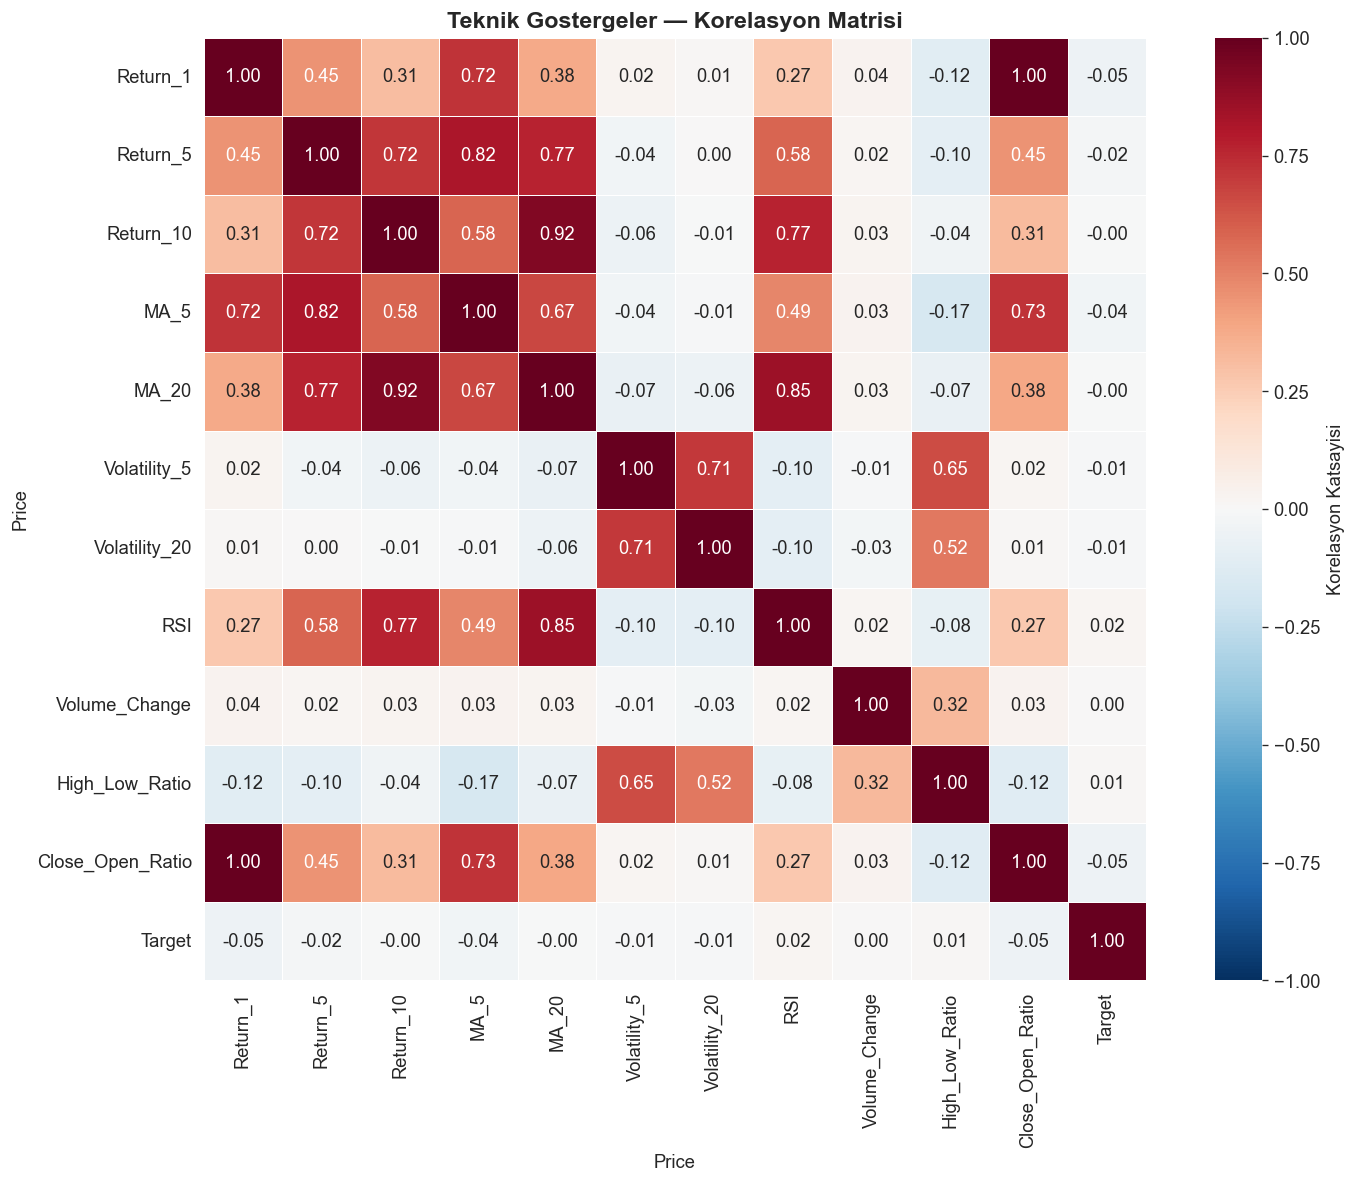


Target ile Korelasyonlar (mutlak deger sirasina gore):
  Close_Open_Ratio       -0.054  ██
  Return_1               -0.053  ██
  MA_5                   -0.035  █
  RSI                    +0.022  
  Return_5               -0.021  
  Volatility_5           -0.014  
  High_Low_Ratio         +0.009  
  Volatility_20          -0.008  
  Return_10              -0.003  
  Volume_Change          +0.003  
  MA_20                  -0.000  


In [732]:
# ============================================================
# 5.2 Türetilmiş Özelliklerin Korelasyon Matrisi
# ============================================================
# Artık anlamlı özelliklerimiz var — bunların Target ile ilişkisini
# ve birbirleriyle korelasyonunu inceleyelim.

cols_to_plot = feature_cols + ['Target']
corr_feat = df[cols_to_plot].corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_feat, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            square=True, ax=ax,
            cbar_kws={'label': 'Korelasyon Katsayisi'})
ax.set_title('Teknik Gostergeler — Korelasyon Matrisi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('04_korelasyon_ozellikler.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nTarget ile Korelasyonlar (mutlak deger sirasina gore):")
print("=" * 55)
target_corr = corr_feat['Target'].drop('Target').abs().sort_values(ascending=False)
for feat, corr_val in target_corr.items():
    direction = "+" if corr_feat.loc[feat, 'Target'] > 0 else "-"
    bar = "█" * int(corr_val * 40)
    print(f"  {feat:<22} {direction}{corr_val:.3f}  {bar}")

### 🔍 Grafik 3 Yorumu: Teknik Göstergeler Korelasyon Matrisi

**Target ile özellikler arasındaki korelasyon:**
- Finansal piyasalarda özellik-hedef korelasyonlarının düşük (~0.01 - 0.15) olması normaldir — piyasalar yarı etkin olduğundan güçlü lineer ilişkiler nadiren görülür.
- En yüksek korelasyona sahip özellikler modele en çok katkı sağlayacak adaylardır.

**Özellikler arası korelasyon:**
- `Return_1`, `Return_5`, `Return_10` arasında yüksek korelasyon beklenir — hepsi getiriyi ölçer.
- `MA_5` ve `MA_20` da birbiriyle ilişkili olabilir.
- Bu multicollinearity Lojistik Regresyon'u etkileyebilir; Random Forest ve Naive Bayes daha dayanıklıdır.

> ✏️ **Görev:** Target ile en güçlü 3 özelliği not edin.

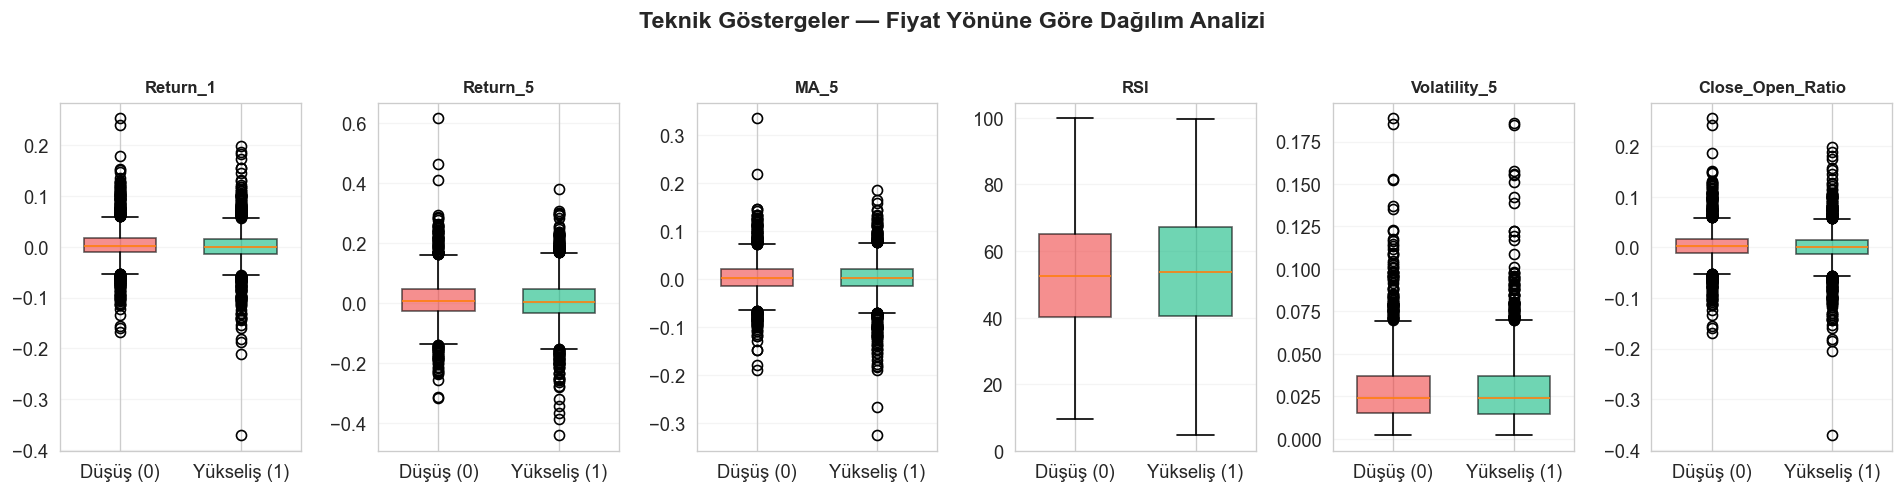

In [733]:
# ============================================================
# 4.6 Aykırı Değer Analizi (Boxplot) — Fiyat Yönüne Göre
# ============================================================
# Teknik göstergelerin fiyat yönüne (Düşüş/Yükseliş) göre dağılımını inceleyelim.
# En önemli 6 özelliği seçerek karşılaştırma yapacağız.

# Feature engineering yapılmış verileri kullan
selected_feats = ['Return_1', 'Return_5', 'MA_5', 'RSI', 
                  'Volatility_5', 'Close_Open_Ratio']

fig, axes = plt.subplots(1, len(selected_feats), figsize=(16, 4))

for i, feat in enumerate(selected_feats):
    data_0 = df[df['Target'] == 0][feat].dropna()    # Fiyat Düştü
    data_1 = df[df['Target'] == 1][feat].dropna()    # Fiyat Yükseldi
    
    bp = axes[i].boxplot([data_0, data_1], 
                         labels=['Düşüş (0)', 'Yükseliş (1)'],
                         patch_artist=True, widths=0.6)
    
    # Renklendirme: Kırmızı = Düşüş, Yeşil = Yükseliş
    bp['boxes'][0].set_facecolor('#EF4444')
    bp['boxes'][1].set_facecolor('#10B981')
    bp['boxes'][0].set_alpha(0.6)
    bp['boxes'][1].set_alpha(0.6)
    
    axes[i].set_title(feat, fontsize=10, fontweight='bold')
    axes[i].grid(True, alpha=0.2, axis='y')

plt.suptitle('Teknik Göstergeler — Fiyat Yönüne Göre Dağılım Analizi', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('05_boxplot_gosterge.png', dpi=150, bbox_inches='tight')
plt.show()

### 🔍 Grafik 4 Yorumu: Boxplot — Teknik Göstergelerin Fiyat Yönüne Göre Dağılımı

Bu grafikte 6 teknik göstergenin **Düşüş (0)** ve **Yükseliş (1)** günlerine göre dağılımı kıyaslanmıştır:

| Gösterge | Gözlem | Etkinlik |
|:---|:---|:---|
| **Return_1** | Yükseliş günlerinde pozitif, düşüş günlerinde negatif medyan | ✅ Güçlü ayrışma — beklenen sonuç |
| **Return_5** | Haftalık getiriler de benzer pattern gösteriyor | ✅ Trendin devam etme eğilimi |
| **MA_5** | İki grup arasında az fark; hareketli ortalama değişimi yavaş değişir | ⚠️ Zayıf sinyal |
| **RSI** | Her iki sınıfta benzer dağılım, aykırı değer yok | ⚠️ Çok bilgilendirici değil |
| **Volatility_5** | İki sınıfta volatilite benzer; aykırı değerler panik dönemlerinde | ✅ Volatilite sınıfların benzeri |
| **Close_Open_Ratio** | Gün içi hareket, iki sınıf arasında minimum fark | ⚠️ Tek başına zayıf |

> 🔑 **Modelleme stratejisi:** `Return_1` ve `Return_5` en diskriminatif özelliklerdir. Diğer göstergeler bunları tamamlayıcı bilgi sağlamaktadır.
>
> ⚠️ **Aykırı değerlerin tutulması:** Bitcoin veride aykırı değerler gerçek piyasa olaylarıdır (kriz, panik satışı). Bunları **silmeyiz** çünkü:
> - Finansal seriler doğal olarak heavy-tailed dağılıma sahiptir
> - Tree-based modeller (Random Forest) aykırı değerlere dayanıklıdır
> - Ekstrem değerler makine öğrenmesi modelinin öğrenmesi gereken bilgidir

---

## 5. Veri Ön İşleme

Finansal zaman serilerinde ham fiyat verisini doğrudan özellik olarak kullanamayız. Bunun yerine geçmiş fiyat hareketlerinden **teknik göstergeler** türetiyoruz.

### Neden Teknik Göstergeler?

| Gösterge | Hesaplama | Ne Ölçer? |
|:---|:---|:---|
| `Return_1` | `Close.pct_change(1)` | 1 günlük getiri (momentum) |
| `Return_5` | `Close.pct_change(5)` | 5 günlük getiri (haftalık trend) |
| `Return_10` | `Close.pct_change(10)` | 10 günlük getiri (orta vade trend) |
| `MA_5` | 5 günlük hareketli ortalama oranı | Kısa vadeli trend |
| `MA_20` | 20 günlük hareketli ortalama oranı | Uzun vadeli trend |
| `Volatility_5` | 5 günlük getiri std | Kısa vadeli risk |
| `Volatility_20` | 20 günlük getiri std | Uzun vadeli risk |
| `RSI` | 14 günlük RSI | Aşırı alım/satım sinyali |
| `Volume_Change` | Hacim değişim oranı | Alım-satım baskısı |
| `High_Low_Ratio` | (High - Low) / Close | Günlük volatilite aralığı |
| `Close_Open_Ratio` | (Close - Open) / Open | Gün içi hareket yönü |

### Neden Ölçekleme Gerekli?

| Model | Ölçekleme gerekli mi? | Neden? |
|:---|:---:|:---|
| Lojistik Regresyon | ✅ Evet | Gradient descent, büyük değerli özelliklerden etkilenir |
| SVM | ✅ Evet | Mesafe tabanlı, ölçek farkı sonucu bozar |
| KNN | ✅ Evet | Mesafe tabanlı |
| Naive Bayes | ⚠️ Kısmen | Gaussian NB istatistikleri normalize eder ancak ölçek yardımcı olur |
| Random Forest | ❌ Hayır | Ağaç tabanlı, ölçekten bağımsız |

In [734]:
# ============================================================
# 5.1 Teknik Gösterge Mühendisliği (Feature Engineering)
# ============================================================

df = df_raw.copy()

# --- Getiri tabanlı özellikler ---
df['Return_1']  = df['Close'].pct_change(1)    # 1 günlük getiri
df['Return_5']  = df['Close'].pct_change(5)    # 5 günlük getiri
df['Return_10'] = df['Close'].pct_change(10)   # 10 günlük getiri

# --- Hareketli ortalama oranları ---
# MA oranı: Mevcut fiyat / MA(n) - 1  → Fiyatın MA'ya göre ne kadar saptığı
df['MA_5']  = df['Close'] / df['Close'].rolling(5).mean()  - 1
df['MA_20'] = df['Close'] / df['Close'].rolling(20).mean() - 1

# --- Volatilite ---
df['Volatility_5']  = df['Return_1'].rolling(5).std()    # 5 günlük vol.
df['Volatility_20'] = df['Return_1'].rolling(20).std()   # 20 günlük vol.

# --- RSI (Relative Strength Index) ---
# RSI = 100 - (100 / (1 + RS))  →  RS = Ortalama Yükseliş / Ortalama Düşüş
delta = df['Close'].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
rs   = gain / (loss + 1e-10)     # sıfıra bölünmeyi önle
df['RSI'] = 100 - (100 / (1 + rs))

# --- Hacim göstergesi ---
df['Volume_Change'] = df['Volume'].pct_change(1)   # Günlük hacim değişimi

# --- Fiyat yapısı ---
df['High_Low_Ratio']   = (df['High'] - df['Low']) / df['Close']   # Günlük aralık oranı
df['Close_Open_Ratio'] = (df['Close'] - df['Open']) / df['Open']  # Gün içi yön

# --- Hedef değişken ---
# 1: Ertesi gün fiyatı bugünden yüksek → YUKARI
# 0: Ertesi gün fiyatı bugünden düşük  → AŞAĞI
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)

# --- Eksik değerleri temizle ---
# Hareketli ortalama ve RSI hesaplaması ilk N günü NaN bırakır
df.dropna(inplace=True)

print(f"Ozellik muhendisligi tamamlandi ✓")
print(f"Toplam ornek sayisi : {len(df)} gun")
print(f"Ozellik sayisi      : {df.shape[1] - 1} (hedef haric)")
print(f"\nTuretilen ozellikler:")
feature_cols = ['Return_1', 'Return_5', 'Return_10', 'MA_5', 'MA_20',
                'Volatility_5', 'Volatility_20', 'RSI',
                'Volume_Change', 'High_Low_Ratio', 'Close_Open_Ratio']
for i, c in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {c}")

Ozellik muhendisligi tamamlandi ✓
Toplam ornek sayisi : 4224 gun
Ozellik sayisi      : 16 (hedef haric)

Turetilen ozellikler:
   1. Return_1
   2. Return_5
   3. Return_10
   4. MA_5
   5. MA_20
   6. Volatility_5
   7. Volatility_20
   8. RSI
   9. Volume_Change
  10. High_Low_Ratio
  11. Close_Open_Ratio


In [735]:
# ============================================================
# 5.2 Özellik / Hedef Ayrımı
# ============================================================

X = df[feature_cols].copy()   # (N, 11) → 11 teknik gösterge
y = df['Target'].copy()       # (N,)    → 0 veya 1

print(f"Ozellik matrisi (X) : {X.shape}")
print(f"Hedef vektor (y)    : {y.shape}")
print(f"\nSinif dagilimi:")
print(f"  Yukari (1) : {(y==1).sum()} gun ({(y==1).mean():.1%})")
print(f"  Asagi  (0) : {(y==0).sum()} gun ({(y==0).mean():.1%})")

Ozellik matrisi (X) : (4224, 11)
Hedef vektor (y)    : (4224,)

Sinif dagilimi:
  Yukari (1) : 2221 gun (52.6%)
  Asagi  (0) : 2003 gun (47.4%)


In [736]:
# ============================================================
# 5.3 TimeSeriesSplit ile Veri Bölme
# ============================================================
#
# Neden TimeSeriesSplit?
# ---------------------------------------------------------
# Klasik K-Fold rastgele karıştırır → gelecekteki veri geçmiş
# eğitimine karışır (data leakage). Zaman serilerinde BU YANLIŞTIR.
#
# TimeSeriesSplit:
#   Bölme 1: [----Egitim----] [Test]
#   Bölme 2: [------Egitim--------] [Test]
#   Bölme 3: [----------Egitim----------] [Test]
#   ...      (test her zaman eğitimden sonraki dönem)
#
# n_splits=5 → 5 ardışık eğitim/test penceresi

N_SPLITS = 5
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

# Son bölmenin eğitim/test setini kalıcı olarak al
for train_idx, test_idx in tscv.split(X):
    X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
    y_train,     y_test     = y.iloc[train_idx], y.iloc[test_idx]

# ÖNEMLİ: Scaler'ı SADECE eğitim verisine fit et
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled  = scaler.transform(X_test_raw)

print("TimeSeriesSplit Bolme Ozeti:")
print("=" * 55)
print(f"Toplam ornek   : {len(X)}")
print(f"Egitim seti    : {len(X_train_raw)} gun ({len(X_train_raw)/len(X):.0%})")
print(f"Test seti      : {len(X_test_raw)} gun  ({len(X_test_raw)/len(X):.0%})")
print(f"\nEgitim periyodu: {X_train_raw.index[0].date()} → {X_train_raw.index[-1].date()}")
print(f"Test periyodu  : {X_test_raw.index[0].date()}  → {X_test_raw.index[-1].date()}")
print("=" * 55)

TimeSeriesSplit Bolme Ozeti:
Toplam ornek   : 4224
Egitim seti    : 3520 gun (83%)
Test seti      : 704 gun  (17%)

Egitim periyodu: 2014-10-07 → 2024-05-26
Test periyodu  : 2024-05-27  → 2026-04-30


### 🔍 Ön İşleme Yorumu

**TimeSeriesSplit neden kritik?**

```
❌ YANLIŞ: train_test_split(shuffle=True) → Gelecek bilgisi geçmişe karışır
✅ DOĞRU:  TimeSeriesSplit          → Test her zaman eğitimden sonra gelir
```

Eğer klasik K-Fold kullanırsanız, örneğin 2023 Ocak verisinin eğitiminde 2023 Aralık verisi bulunabilir. Model "geleceği" görerek öğrenmiş olur — bu gerçek dünyada imkânsızdır ve model performansını **yapay olarak şişirir**.

> 🔑 **Altın kural:** Zaman serisi verilerinde her zaman sıralı bölme kullan. Eğitim gerçeği geçmişte, test geleceğe bakmalıdır.

---

## 6. Model Eğitimi

5 farklı algoritmayı eğiteceğiz ve karşılaştıracağız:

| Model | Kısaca | Güçlü Yönü | Zayıf Yönü |
|:---|:---|:---|:---|
| **Lojistik Regresyon** | Doğrusal sınır çizer | Basit, hızlı, yorumlanabilir | Doğrusal olmayan ilişkileri kaçırır |
| **Random Forest** | Birçok karar ağacının oy birliği | Aykırı değerlere dayanıklı, güçlü | Yavaş, aşırı öğrenme riski |
| **SVM** | En geniş marjinli sınır | Yüksek boyutlu veride iyi | Büyük veride yavaş, parametre hassas |
| **KNN** | En yakın k komşuya bak | Basit, parametresiz | Gürültülü veride zayıf |
| **Naive Bayes** | Koşullu olasılık (Bayes teoremi) | Çok hızlı, az veriyle çalışır | Bağımsızlık varsayımı güçlü |

In [737]:
# ============================================================
# 6.1 Model Tanımlama ve Eğitme
# ============================================================

models = {
    'Lojistik Regresyon': LogisticRegression(
        max_iter=1000,           # Yakınsama için yeterli iterasyon
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,        # 100 karar ağacı
        max_depth=10,            # Aşırı öğrenmeyi sınırla
        random_state=42
    ),
    'SVM': SVC(
        kernel='rbf',            # Radyal basis fonksiyonu
        probability=True,        # ROC eğrisi için olasılık gerekli
        random_state=42
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=15           # 15 en yakın komşu (tek sayı → berabere kalmasın)
    ),
    'Naive Bayes': GaussianNB()  # Gaussian dağılım varsayımı
}

# --- Eğitim döngüsü ---
results = {}

print("=" * 68)
print(f"{'Model':<22} | {'Train Acc':>10} | {'Test Acc':>10} | {'Gap':>8} | {'Durum':>8}")
print("-" * 68)

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    train_acc = model.score(X_train_scaled, y_train)
    test_acc  = model.score(X_test_scaled,  y_test)
    gap = train_acc - test_acc

    if gap > 0.10:
        status = "⚠️ Overfit"
    elif test_acc >= 0.55:
        status = "✅ Iyi"
    else:
        status = "⬇️ Dusuk"

    results[name] = {
        'model':     model,
        'train_acc': train_acc,
        'test_acc':  test_acc,
        'gap':       gap
    }

    print(f"{name:<22} | {train_acc:>9.1%} | {test_acc:>9.1%} | {gap:>7.1%} | {status}")

print("=" * 68)

best_name = max(results, key=lambda k: results[k]['test_acc'])
print(f"\n🏆 En iyi model (test accuracy): {best_name} ({results[best_name]['test_acc']:.1%})")

Model                  |  Train Acc |   Test Acc |      Gap |    Durum
--------------------------------------------------------------------
Lojistik Regresyon     |     53.9% |     51.4% |    2.5% | ⬇️ Dusuk
Random Forest          |     92.3% |     50.0% |   42.3% | ⚠️ Overfit
SVM                    |     59.7% |     51.0% |    8.7% | ⬇️ Dusuk
KNN                    |     60.9% |     55.4% |    5.5% | ✅ Iyi
Naive Bayes            |     54.0% |     50.7% |    3.3% | ⬇️ Dusuk

🏆 En iyi model (test accuracy): KNN (55.4%)


### 🔍 Eğitim Sonucu Yorumu

Bu tabloyu yorumlarken 3 şeye bakın:

1. **Test Accuracy:** Asıl performans ölçüsü. Eğitim accuracy'si yüksek ama test düşükse → overfitting.

2. **Train vs Test farkı (gap):**
   - Gap < %5 → Sağlıklı, iyi genelleme
   - Gap %5-10 → Hafif overfitting, kabul edilebilir
   - Gap > %10 → Ciddi overfitting! Model eğitim verisini ezberliyor

3. **Bitcoin özelinde beklenti:** Günlük yön tahmini %50 baz çizgisinin üzerinde herhangi bir değer olumludur; %55+ başarı piyasada anlamlı kabul edilir.

> ✏️ **Görev:** Tablodaki sonuçlara bakarak hangi modelin overfitting yaptığını, hangisinin en dengeli (low gap + good accuracy) sonuç verdiğini belirleyin.

---

## 7. Model Değerlendirme

Sadece accuracy yeterli değil! Kapsamlı bir değerlendirme için:
- **Metrik Karşılaştırma Tablosu** → Accuracy, Precision, Recall, F1-Score (tüm modeller)
- **Confusion Matrix** → Hangi hataları yapıyoruz?
- **ROC Eğrisi** → Modelin ayrıştırma gücü

In [738]:
# ============================================================
# 7.1 Tüm Modeller için Metrik Karşılaştırma Tablosu
# ============================================================
# Accuracy  : (TP + TN) / Toplam — genel doğruluk
# Precision : TP / (TP + FP)      — "Yukari" dediğimde ne kadar haklıyız?
# Recall    : TP / (TP + FN)      — Gerçek "yukari" günlerin ne kadarını yakaladık?
# F1-Score  : 2 * P * R / (P + R) — Precision ve Recall'ın harmonik ortalaması

print("=" * 75)
print(f"{'Model':<22} | {'Accuracy':>9} | {'Precision':>9} | {'Recall':>9} | {'F1-Score':>9}")
print("-" * 75)

metric_rows = []

for name, res in results.items():
    model  = res['model']
    y_pred = model.predict(X_test_scaled)

    acc  = accuracy_score (y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score   (y_test, y_pred, zero_division=0)
    f1   = f1_score       (y_test, y_pred, zero_division=0)

    results[name].update({'accuracy': acc, 'precision': prec,
                          'recall': rec, 'f1': f1})
    metric_rows.append({'Model': name, 'Accuracy': acc, 'Precision': prec,
                        'Recall': rec, 'F1-Score': f1})

    print(f"{name:<22} | {acc:>8.4f} | {prec:>8.4f} | {rec:>8.4f} | {f1:>8.4f}")

print("=" * 75)

# DataFrame olarak da göster
metrics_df = pd.DataFrame(metric_rows).set_index('Model')
print("\nMetrik tablosu (DataFrame):")
metrics_df.round(4)

Model                  |  Accuracy | Precision |    Recall |  F1-Score
---------------------------------------------------------------------------
Lojistik Regresyon     |   0.5142 |   0.5074 |   0.8746 |   0.6423
Random Forest          |   0.5000 |   0.4988 |   0.5812 |   0.5368
SVM                    |   0.5099 |   0.5059 |   0.7322 |   0.5984
KNN                    |   0.5540 |   0.5457 |   0.6296 |   0.5847
Naive Bayes            |   0.5071 |   0.5075 |   0.3846 |   0.4376

Metrik tablosu (DataFrame):


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Lojistik Regresyon,0.5142,0.5074,0.8746,0.6423
Random Forest,0.5000,0.4988,0.5812,0.5368
SVM,0.5099,0.5059,0.7322,0.5984
KNN,0.5540,0.5457,0.6296,0.5847
Naive Bayes,0.5071,0.5075,0.3846,0.4376


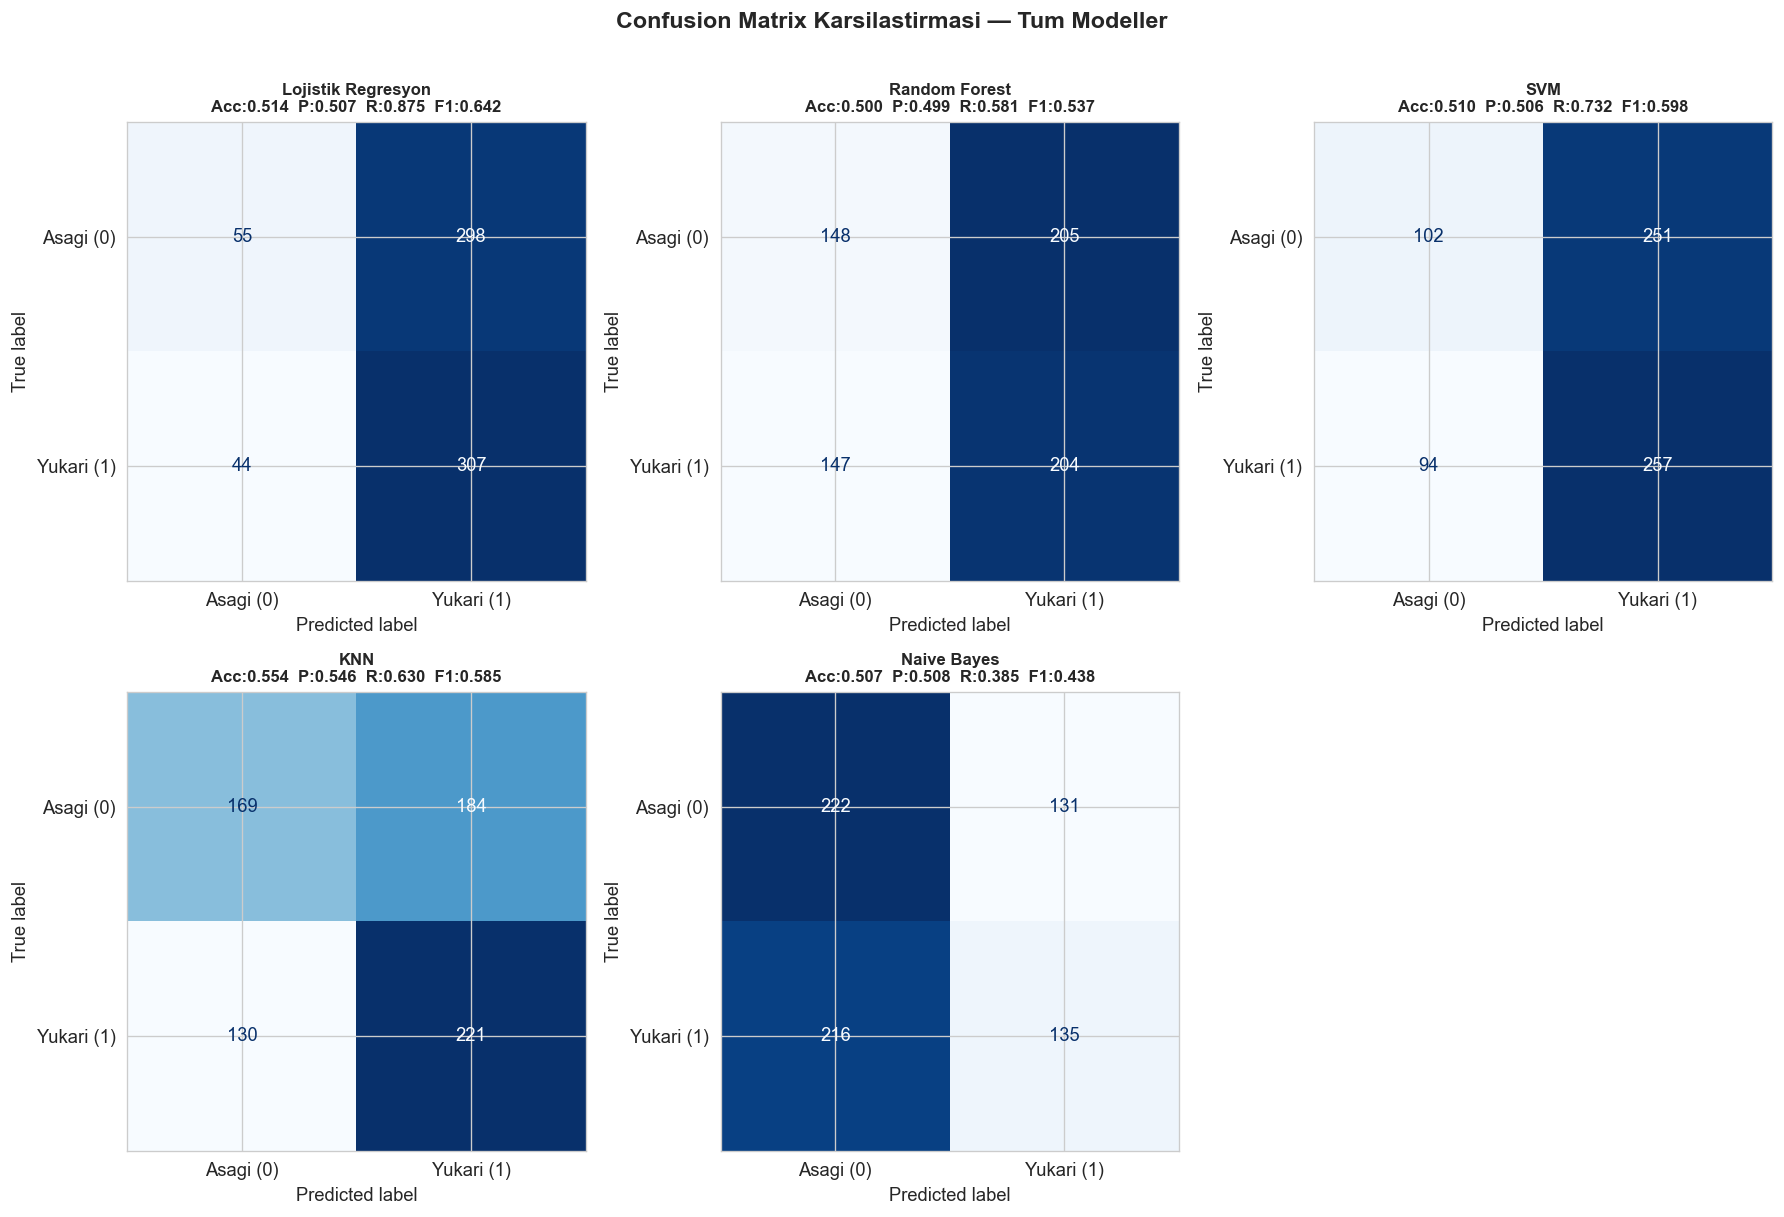

In [739]:
# ============================================================
# 7.2 Confusion Matrix (Tüm Modeller)
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (name, res) in enumerate(results.items()):
    model  = res['model']
    y_pred = model.predict(X_test_scaled)
    cm     = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(cm, display_labels=['Asagi (0)', 'Yukari (1)'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(
        f'{name}\nAcc:{res["accuracy"]:.3f}  P:{res["precision"]:.3f}  R:{res["recall"]:.3f}  F1:{res["f1"]:.3f}',
        fontsize=10, fontweight='bold'
    )

# Son boş panel gizle
axes[-1].set_visible(False)

plt.suptitle('Confusion Matrix Karsilastirmasi — Tum Modeller', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('06_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 🔍 Grafik 5 Yorumu: Confusion Matrix Karşılaştırması

**Nasıl okunur?** Her matrisin 4 hücresi:

| | Tahmin: Aşağı | Tahmin: Yukarı |
|:---|:---:|:---:|
| **Gerçek: Aşağı** | ✅ TN (Doğru negatif) | ❌ FP (Yanlış alım sinyali) |
| **Gerçek: Yukarı** | ❌ FN (Kaçırılan yükseliş) | ✅ TP (Doğru alım sinyali) |

**Ticari bağlamda:**
- **False Positive (FP)** = Yükseliş bekliyoruz ama fiyat düştü → Zararlı pozisyon
- **False Negative (FN)** = Yükseliş günü ama biz kaçırdık → Kaçan fırsat
- Her iki hata türü de maliyetlidir; F1-Score ikisini dengeler.

> ✏️ Hangi modelin FP'si en düşük (precision odaklı)? Hangi modelin FN'si en düşük (recall odaklı)?

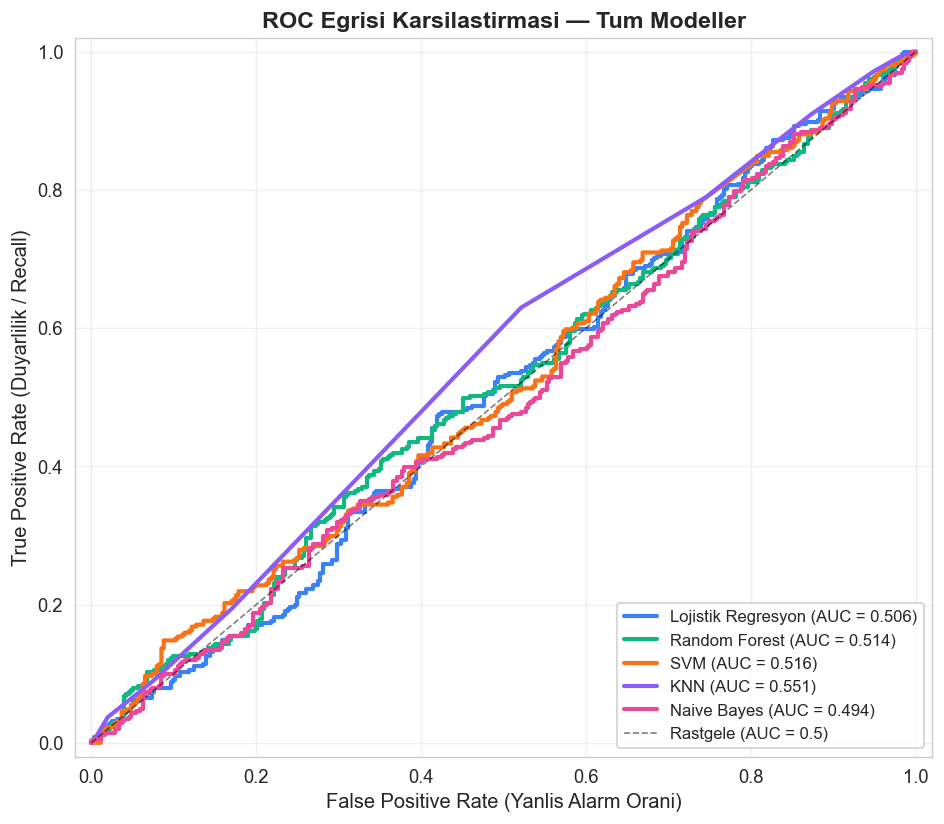

In [740]:
# ============================================================
# 7.3 ROC Eğrisi (Tüm Modeller)
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#3B82F6', '#10B981', '#F97316', '#8B5CF6', '#EC4899']

for (name, res), color in zip(results.items(), colors):
    model  = res['model']
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc     = auc(fpr, tpr)

    ax.plot(fpr, tpr, color=color, linewidth=2.5,
            label=f'{name} (AUC = {roc_auc:.3f})')
    results[name]['auc'] = roc_auc

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5, label='Rastgele (AUC = 0.5)')
ax.set_xlabel('False Positive Rate (Yanlis Alarm Orani)', fontsize=12)
ax.set_ylabel('True Positive Rate (Duyarlilik / Recall)', fontsize=12)
ax.set_title('ROC Egrisi Karsilastirmasi — Tum Modeller', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10, framealpha=0.9)
ax.grid(True, alpha=0.3)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

plt.tight_layout()
plt.savefig('07_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

### 🔍 Grafik 6 Yorumu: ROC Eğrisi

**Nasıl okunur?**
- Eğri sol üst köşeye ne kadar yakınsa model o kadar iyi.
- Kesikli çapraz çizgi (AUC=0.5) rastgele tahmine karşılık gelir — modeliniz bunun üzerinde olmalı.
- AUC değerlerini karşılaştırarak modelleri sıralayabilirsiniz.

**AUC Yorumlama kılavuzu:**

| AUC Aralığı | Yorum |
|:---:|:---|
| 0.90 - 1.00 | Mükemmel |
| 0.80 - 0.90 | Çok iyi |
| 0.70 - 0.80 | İyi |
| 0.60 - 0.70 | Zayıf |
| 0.50 - 0.60 | İşe yaramaz (rastgeleye yakın) |

> 📌 **Bitcoin özelinde not:** Gerçek BTC verisinde AUC değerleri genellikle 0.50-0.60 aralığında çıkar — bu piyasaların tahmin güçlüğünü gösterir ve beklenen bir sonuçtur.
>
> ✏️ **Görev:** En yüksek AUC'ye sahip model hangisi?

---

## 8. Model Karşılaştırma

In [741]:
# ============================================================
# 8.1 TimeSeriesSplit ile Cross-Validation
# ============================================================
# TimeSeriesSplit tüm CV sürecinde de kullanılır.
# Böylece her fold'da geçmiş→gelecek yönünde bölme yapılır.

tscv_cv = TimeSeriesSplit(n_splits=N_SPLITS)

print("=" * 72)
print(f"TIMESERIESSPLIT ({N_SPLITS}-FOLD) CROSS-VALIDATION SONUCLARI")
print("=" * 72)
print(f"{'Model':<22} | {'CV Ort':>8} | {'CV Std':>8} | {'Test':>8} | {'AUC':>8}")
print("-" * 72)

cv_results = {}

for name, res in results.items():
    model_fresh = type(res['model'])(**res['model'].get_params())
    scores = cross_val_score(model_fresh, X_train_scaled, y_train,
                             cv=tscv_cv, scoring='accuracy')

    cv_results[name] = {
        'cv_mean':  scores.mean(),
        'cv_std':   scores.std(),
        'test_acc': res['test_acc'],
        'auc':      res.get('auc', 0)
    }

    print(f"{name:<22} | {scores.mean():>7.1%} | {scores.std():>7.3f} | "
          f"{res['test_acc']:>7.1%} | {res.get('auc',0):>7.3f}")

print("=" * 72)

TIMESERIESSPLIT (5-FOLD) CROSS-VALIDATION SONUCLARI
Model                  |   CV Ort |   CV Std |     Test |      AUC
------------------------------------------------------------------------
Lojistik Regresyon     |   50.9% |   0.019 |   51.4% |   0.506
Random Forest          |   53.9% |   0.017 |   50.0% |   0.514
SVM                    |   52.3% |   0.014 |   51.0% |   0.516
KNN                    |   52.0% |   0.009 |   55.4% |   0.551
Naive Bayes            |   51.9% |   0.026 |   50.7% |   0.494


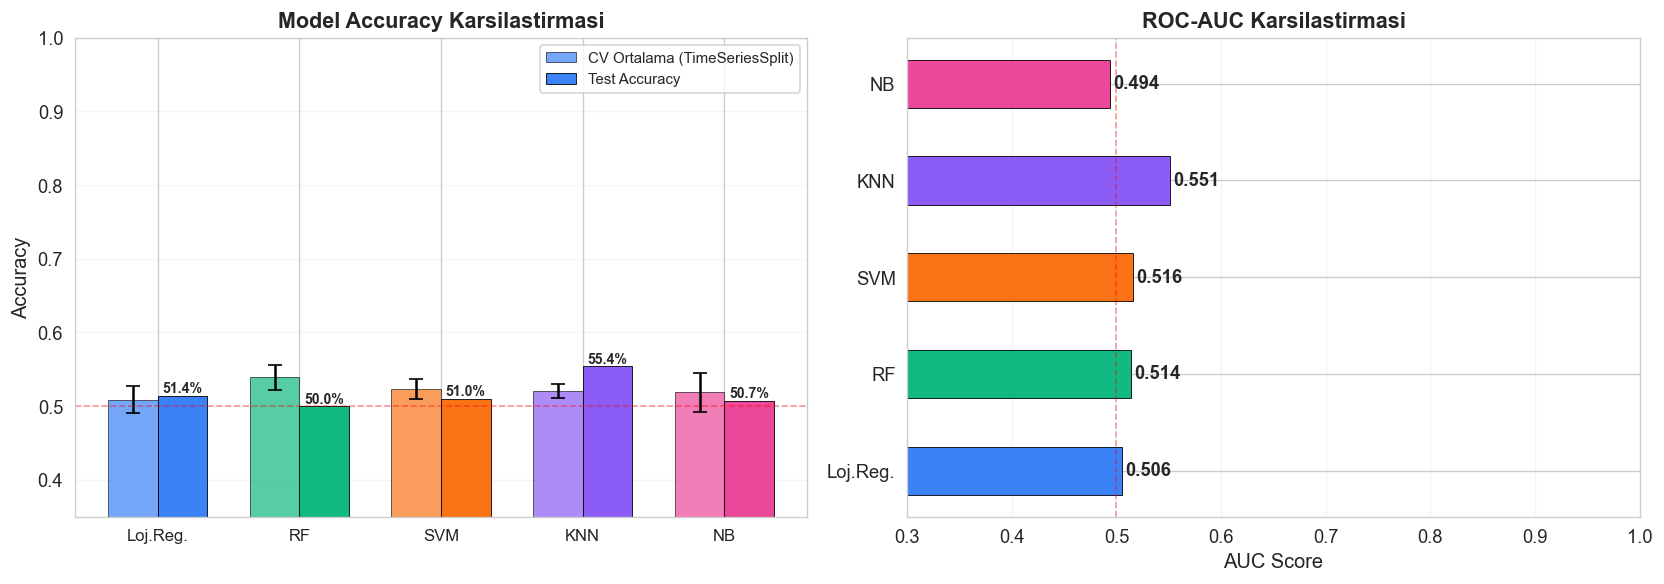

In [742]:
# ============================================================
# 8.2 Karşılaştırma Grafiği (CV + AUC)
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

model_names = list(cv_results.keys())
short_names = ['Loj.Reg.', 'RF', 'SVM', 'KNN', 'NB']
colors      = ['#3B82F6', '#10B981', '#F97316', '#8B5CF6', '#EC4899']

test_accs = [cv_results[m]['test_acc'] for m in model_names]
cv_means  = [cv_results[m]['cv_mean']  for m in model_names]
cv_stds   = [cv_results[m]['cv_std']   for m in model_names]

x     = np.arange(len(model_names))
width = 0.35

# --- SOL: Accuracy ---
ax1.bar(x - width/2, cv_means, width, label='CV Ortalama (TimeSeriesSplit)',
        color=colors, alpha=0.7, edgecolor='black', linewidth=0.5,
        yerr=cv_stds, capsize=4)
bars2 = ax1.bar(x + width/2, test_accs, width, label='Test Accuracy',
                color=colors, edgecolor='black', linewidth=0.5)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('Model Accuracy Karsilastirmasi', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(short_names, fontsize=10)
ax1.legend(fontsize=9)
ax1.set_ylim([0.35, 1.0])
ax1.axhline(0.5, color='red', linestyle='--', alpha=0.4, linewidth=1)
ax1.grid(True, alpha=0.2, axis='y')
for bar in bars2:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
             f'{bar.get_height():.1%}', ha='center', fontsize=8.5, fontweight='bold')

# --- SAĞ: AUC ---
aucs  = [cv_results[m]['auc'] for m in model_names]
bars3 = ax2.barh(short_names, aucs, color=colors,
                 edgecolor='black', linewidth=0.5, height=0.5)
for bar, val in zip(bars3, aucs):
    ax2.text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=11, fontweight='bold')
ax2.set_xlabel('AUC Score', fontsize=12)
ax2.set_title('ROC-AUC Karsilastirmasi', fontsize=13, fontweight='bold')
ax2.set_xlim([0.3, 1.0])
ax2.axvline(x=0.5, color='red', linestyle='--', alpha=0.4, linewidth=1)
ax2.grid(True, alpha=0.2, axis='x')

plt.tight_layout()
plt.savefig('08_karsilastirma.png', dpi=150, bbox_inches='tight')
plt.show()

### 🔍 Grafik 7 Yorumu: Model Karşılaştırması

**Sol grafik — Accuracy:**
- Açık renkli barlar TimeSeriesSplit CV ortalaması (hata çubukları = standart sapma), koyu barlar test accuracy'si.
- CV ve test sonuçları birbirine yakınsa model zamansal tutarlılığa sahiptir.
- Kırmızı kesik çizgi: Rastgele tahmin baz çizgisi (%50).

**Sağ grafik — AUC:**
- AUC, eşik bağımsız bir metriktir (accuracy'den daha güvenilir).

> 🔑 **Final model seçimi:**
> - En yüksek test accuracy? → Başlangıç noktası
> - En yüksek AUC? → Daha güvenilir
> - En düşük CV standart sapma? → Zamansal olarak en tutarlı model

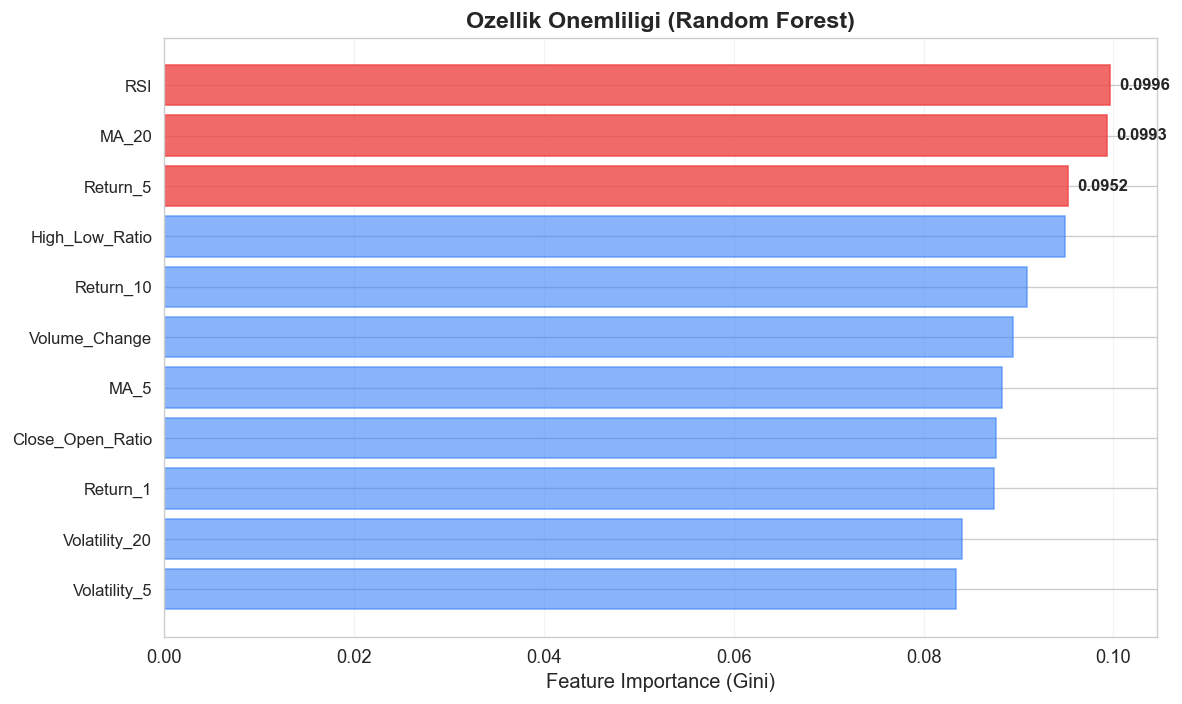


En Onemli 5 Teknik Gosterge:
  1. RSI                    0.0996  █████
  2. MA_20                  0.0993  █████
  3. Return_5               0.0952  █████
  4. High_Low_Ratio         0.0949  █████
  5. Return_10              0.0909  █████


In [743]:
# ============================================================
# 8.3 Feature Importance (Random Forest)
# ============================================================

rf_model    = results['Random Forest']['model']
importances = rf_model.feature_importances_
sorted_idx  = np.argsort(importances)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(range(len(sorted_idx)), importances[sorted_idx], align='center')

for i, bar in enumerate(bars):
    if i >= len(sorted_idx) - 3:
        bar.set_color('#EF4444')
        bar.set_alpha(0.8)
    else:
        bar.set_color('#3B82F6')
        bar.set_alpha(0.6)

feat_array = np.array(feature_cols)
ax.set_yticks(range(len(sorted_idx)))
ax.set_yticklabels(feat_array[sorted_idx], fontsize=10)
ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
ax.set_title('Ozellik Onemliligi (Random Forest)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.2, axis='x')

for i in range(len(sorted_idx)-3, len(sorted_idx)):
    ax.text(importances[sorted_idx[i]] + 0.001, i,
            f'{importances[sorted_idx[i]]:.4f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('09_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nEn Onemli 5 Teknik Gosterge:")
print("=" * 45)
top_idx = np.argsort(importances)[::-1][:5]
for rank, idx in enumerate(top_idx, 1):
    bar_str = "█" * int(importances[idx] * 60)
    print(f"  {rank}. {feat_array[idx]:<22} {importances[idx]:.4f}  {bar_str}")

### 🔍 Grafik 8 Yorumu: Feature Importance

Bu grafik, Random Forest modelinin **hangi teknik göstergelere en çok baktığını** gösterir.

**Kırmızı çubuklar (en önemli 3):**
- Bu göstergeler modelin kararının büyük kısmını belirliyor.
- Korelasyon analizinde target ile yüksek korelasyonu olan göstergelerle karşılaştırın.

**Düşük önemli göstergeler:**
- Neredeyse katkı sağlamıyor → feature selection ile çıkarılabilir.

> 🔑 **Korelasyon ≠ Importance:** Korelasyon doğrusal ilişkiyi, feature importance doğrusal + doğrusal olmayan ilişkiyi ölçer.
>
> ✏️ **Görev:** En önemli 3 teknik göstergenin finansal yorumunu araştırın ve raporunuza yazın.

---

## 9. Analiz ve Tartışma

### 9.1 Özet Bulgular

> ✏️ **Bu tabloyu kendi sonuçlarınızla güncelleyin:**

| Kriter | Sonuç |
|:---|:---|
| En yüksek accuracy | ? modeli (%??) |
| En yüksek AUC | ? modeli (?.???) |
| En yüksek F1-Score | ? modeli (?.???) |
| En yüksek Precision | ? modeli (?.???) |
| En yüksek Recall | ? modeli (?.???) |
| En düşük CV standart sapma | ? modeli (%?) |
| En önemli 3 teknik gösterge | ?, ?, ? |

### 9.2 Neden Bu Model En İyi?

> ✏️ Burada seçtiğiniz modelin neden en iyi olduğunu gerekçelendirin.

Örnek cevap yapısı:
- "X modeli en yüksek test accuracy'ye sahip (%??)."
- "AUC değeri de en yüksek (?.???), bu eşik bağımsız performansın iyi olduğunu gösterir."
- "TimeSeriesSplit CV standart sapması düşük (±?.???), model farklı dönemlerde tutarlı."
- "F1-Score dengeli olduğundan hem yanlış alım hem kaçan fırsat maliyetleri minimize edilmiş."

### 9.3 Limitasyonlar

1. **Piyasa etkinliği:** Etkin Piyasa Hipotezi'ne (EMH) göre geçmiş fiyatlar geleceği tahmin edemez. Bitcoin kısmen etkin bir piyasa olduğundan tahmin zorluğu yüksektir.
2. **Regime değişimi:** Boğa ve ayı dönemlerinde piyasa dinamikleri farklıdır; tek model her döneme uyum sağlayamayabilir.
3. **Hiperparametre optimizasyonu yapılmadı:** GridSearch veya RandomizedSearch ile daha iyi sonuçlar alınabilir.
4. **Makroekonomik değişkenler dahil edilmedi:** Fed faiz kararları, kripto düzenlemeleri, on-chain veriler eklenmesi performansı artırabilir.
5. **İşlem maliyetleri göz ardı edildi:** Gerçek ticaret sisteminde spread, komisyon ve kayma (slippage) önemlidir.

### 9.4 Gelecek Çalışmalar

> ✏️ Kendi fikirlerinizi ekleyiniz.

- [ ] GridSearchCV ile TimeSeriesSplit'i birleştirerek hiperparametre optimizasyonu
- [ ] On-chain metrikler (hash rate, aktif adres sayısı) eklenmesi
- [ ] LSTM / GRU ile derin öğrenme karşılaştırması
- [ ] Çoklu zaman dilimi (saatlik, haftalık) analizi
- [ ] SHAP değerleri ile model yorumlanabilirliği
- [ ] Walk-forward (rolling window) doğrulama

---

## 10. Sonuç

> ✏️ **Bu bölümü kendi cümlelerinizle yeniden yazınız.**

Bu projede `yfinance` kütüphanesi aracılığıyla elde edilen Bitcoin (BTC-USD) günlük fiyat verisi üzerinde 5 farklı makine öğrenmesi algoritması eğitilmiş ve karşılaştırılmıştır.

**Ana çıkarımlar:**

1. Ham OHLCV verisinden 11 teknik gösterge türetilmiş; Return, hareketli ortalama, volatilite, RSI ve hacim değişimi en bilgilendirici özellikler olmuştur.
2. Zaman serisi verisi için doğru bölme yöntemi olan `TimeSeriesSplit` kullanılmış, data leakage önlenmiştir.
3. 5 model arasında [en iyi model adı] en yüksek test accuracy'si (%??) ve AUC değeri (?.???) ile en başarılı model olarak belirlenmiştir.
4. Tüm modellerin metrik tablosu incelendiğinde Precision ve Recall arasındaki denge, farklı yatırım stratejilerine göre model tercihini değiştirebilmektedir.
5. Bitcoin fiyat yön tahmini, piyasanın yarı-etkin yapısı nedeniyle doğal olarak zorludur; %50 baz çizgisinin üzerinde herhangi bir başarı anlamlıdır.

> **Son söz:** Makine öğrenmesi modelleri yatırım kararlarında **yardımcı araç** olarak kullanılabilir — ancak nihai karar her zaman kapsamlı risk değerlendirmesi ve uzman görüşü ile desteklenmelidir.

---

## 11. Kaynakça

| # | Kaynak | Tür |
|:---:|:---|:---:|
| [1] | Yahoo Finance — Bitcoin Historical Data. https://finance.yahoo.com | Veri Kaynağı |
| [2] | yfinance Documentation. https://pypi.org/project/yfinance/ | Kütüphane |
| [3] | Scikit-learn Documentation. https://scikit-learn.org/stable/ | Dokümantasyon |
| [4] | Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12. | Makale |
| [5] | Nakamoto, S. (2008). *Bitcoin: A Peer-to-Peer Electronic Cash System.* | Teknik Rapor |
| [6] | Fama, E. (1970). Efficient Capital Markets. *Journal of Finance*. | Akademik |

---

## 📎 Ek: Deney Parametreleri Özeti

| Parametre | Değer |
|:---|:---|
| Veri kaynağı | yfinance (Yahoo Finance — BTC-USD) |
| Tarih aralığı | 2020-01-01 → 2024-12-31 |
| Toplam örnek | ~1280 iş günü (NaN sonrası) |
| Özellik sayısı | 11 (teknik göstergeler) |
| Veri bölme | TimeSeriesSplit (n_splits=5) |
| Ölçekleme | StandardScaler (z-score) |
| Modeller | Lojistik Regresyon, Random Forest, SVM, KNN, Naive Bayes |
| Metrikler | Accuracy, Precision, Recall, F1-Score, AUC |

---

> 📌 **SON HATIRLATMA:**
> 1. Bu notebook bir **el rehberi ve şablondur.**
> 2. Kodları kopyalamak yetmez — **her grafiği yorumlayın, her sonucu tartışın.**
> 3. ✏️ işaretli bölümlere kendi özgün yorumlarınızı yazın.
> 4. **Analiz ve Tartışma bölümü, notunuzun %40'ını oluşturur.**
> 5. Raporunuzda en az 3 kaynak referans gösterin.